In [1]:
import xarray as xr

metamodel_ds = xr.open_dataset("outputs/bulk_metamodel.nc")
metamodel_ds

<xarray.Dataset> Size: 5MB
Dimensions:  (time: 744, site: 338)
Coordinates:
  * time     (time) datetime64[ns] 6kB 2023-01-01 ... 2023-01-31T23:00:00
  * site     (site) int64 3kB 0 1 2 3 4 5 6 7 ... 331 332 333 334 335 336 337
Data variables:
    hs       (time, site) float64 2MB ...
    tp       (time, site) float32 1MB ...
    dm       (time, site) float64 2MB ...
Attributes:
    globwave_name:          significant_wave_height
    long_name:              Significant height of wind and swell waves
    standard_name:          sea_surface_wave_significant_height
    units:                  m
    valid_max:              32000
    valid_min:              0
    coverage_content_type:  modelResult
    mesh:                   SMC

In [2]:
dynamic_ds = xr.open_dataset("SnapWave_CASES_Dynamic/Dynamic_Cases_202301.nc")
dynamic_ds

<xarray.Dataset> Size: 6MB
Dimensions:       (time: 744, stations: 338)
Coordinates:
  * time          (time) datetime64[ns] 6kB 2023-01-01 ... 2023-01-31T23:00:00
    station_name  (stations) |S256 87kB ...
    station_x     (stations) float32 1kB ...
    station_y     (stations) float32 1kB ...
    point_zb      (stations) float32 1kB ...
Dimensions without coordinates: stations
Data variables:
    point_zs      (time, stations) float32 1MB ...
    point_hm0     (time, stations) float32 1MB ...
    point_tp      (time, stations) float32 1MB ...
    point_wavdir  (time, stations) float32 1MB ...
    point_dw      (time, stations) float32 1MB ...
    point_df      (time, stations) float32 1MB ...
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

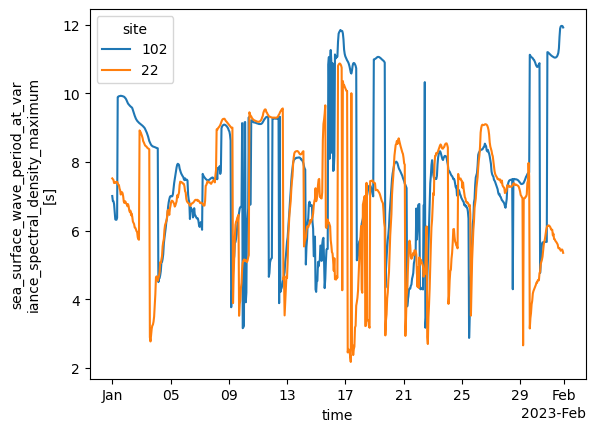

In [29]:
metamodel_ds.isel(site=[102,22])["tp"].plot(hue="site")

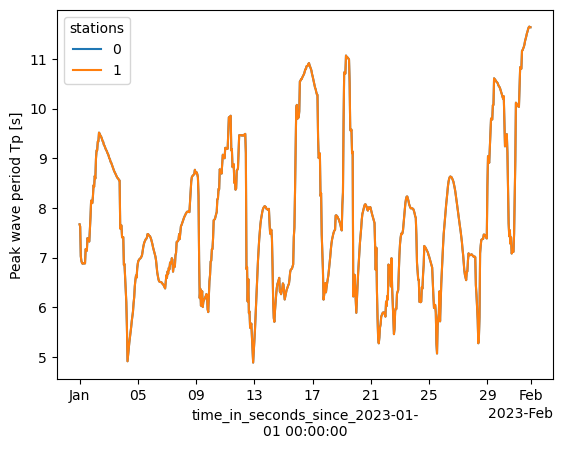

In [35]:
dynamic_ds.isel(stations=[22,222])["point_tp"].plot(hue="stations")

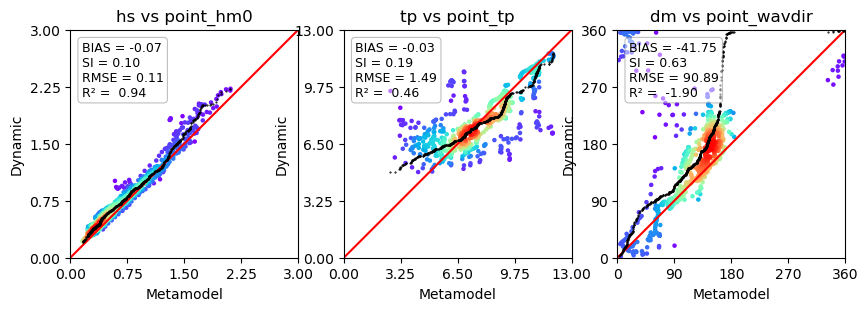

In [12]:
import matplotlib.pyplot as plt
from bluemath_tk.core.plotting.old_scatter import validation_scatter

fig, axes = plt.subplots(1, 3, figsize=(10, 5))

for ax, meta_var, dyna_var in zip(
    axes, ["hs", "tp", "dm"], ["point_hm0", "point_tp", "point_wavdir"]
):
    validation_scatter(
        axs=ax,
        x=metamodel_ds.isel(site=-8)[meta_var].values,
        y=dynamic_ds.isel(stations=-8)[dyna_var].values,
        xlabel="Metamodel",
        ylabel="Dynamic",
        title=f"{meta_var} vs {dyna_var}",
    )